In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

DATA_DIR = Path("../data/raw")

train_path = DATA_DIR / "UNSW_NB15_training-set.csv"
test_path = DATA_DIR / "UNSW_NB15_testing-set.csv"

train_df = pd.read_csv(train_path, low_memory=False)
test_df = pd.read_csv(test_path, low_memory=False)

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)


Training shape: (175341, 45)
Testing shape: (82332, 45)


In [2]:

excluded_columns = ["id", "label", "attack_cat"]

X_train = train_df.drop(columns=excluded_columns)
y_train = train_df["label"].astype(int)

X_test = test_df.drop(columns=excluded_columns)
y_test = test_df["label"].astype(int)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())


Training features: (175341, 42)
Testing features: (82332, 42)

Training target distribution:
label
1    119341
0     56000
Name: count, dtype: int64


In [3]:

categorical_columns = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:", categorical_columns)
print("Number of categorical features:", len(categorical_columns))

print("\nNumber of numerical features:", len(numerical_columns))


Categorical features: ['proto', 'service', 'state']
Number of categorical features: 3

Number of numerical features: 39


In [4]:

def build_preprocessor(numerical_columns, categorical_columns):
    numeric_pipeline = Pipeline([
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numerical_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])

preprocessor = build_preprocessor(
    numerical_columns,
    categorical_columns
)


In [5]:

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

baseline_model.fit(X_train, y_train)

print("Baseline model training completed!")


Baseline model training completed!


In [6]:

y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, y_pred), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    digits=4
))


Accuracy: 0.8097
Balanced accuracy: 0.7913
ROC-AUC: 0.9556

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9476    0.6102    0.7424     37000
      Attack     0.7535    0.9724    0.8491     45332

    accuracy                         0.8097     82332
   macro avg     0.8505    0.7913    0.7957     82332
weighted avg     0.8407    0.8097    0.8011     82332



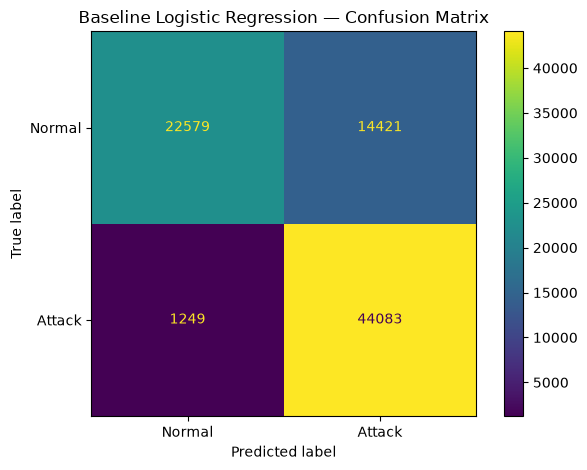

In [7]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)

disp.plot(values_format="d")
plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


In [8]:

import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

baseline_path = MODEL_DIR / "baseline_logistic_regression.joblib"

joblib.dump(baseline_model, baseline_path)

print(f"Baseline model saved to: {baseline_path}")


Baseline model saved to: ..\models\baseline_logistic_regression.joblib
